# 10 — Compare classifiers and longer-history candidates

Run 06–09 and 09b first, then **Restart Kernel and Run All** here. This notebook verifies and reads their latest completed results. It never fits models, searches parameters, changes cutoffs or reads prepared test rows.

**Declared comparison rule:** highest mean 2025 fold AP; lower fold AP standard deviation and then model name break ties. Later validation is descriptive and does not change this rule. Reused folds and cutoff-selection metrics are exploratory evidence, not independent final tests. Equal trial budgets do not make different search spaces equally exhaustive.

The candidate identified here is not automatically deployed. Your existing dashboard checkpoint and its evidence remain unchanged. Fresh integration of a different classifier requires matching anomaly/SHAP exports and a separate decision.

**Active history experiment:** 09b compares two inherited LightGBM settings with 2024 added and a new configuration tuned directly on that longer history. All use identical prepared evaluation rows. Compare algorithms within the original four, history within matched settings, and direct tuning against the two longer-history controls. This is not an equal-training-data algorithm contest. The table includes six candidates from older two-control runs, or seven after a completed direct-history search. Saved outputs below include the completed direct-history search. Run All after a new 09b execution to compare that matching result.


In [1]:
from pathlib import Path
from importlib import reload
import hashlib
import json
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pricecatcher_config as cfg
cfg = reload(cfg)
MODEL_PATTERNS = {
    "Logistic Regression": "06_logistic_regression/*/study_manifest.json",
    "Random Forest": "07_random_forest/*/study_manifest.json",
    "XGBoost": "08_xgboost/*/study_manifest.json",
    "LightGBM": "09_lightgbm/*/study_manifest.json",
    "Longer-history LightGBM (reference)": "09b_longer_history_lightgbm/*/reference/study_manifest.json",
    "Longer-history LightGBM (tuned)": "09b_longer_history_lightgbm/*/tuned/study_manifest.json",
}
def file_hash(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()
# Optional direct-history search. Resolve it from the same run as both controls,
# never from an older search whose parents happen to have different provenance.
history_runs = sorted((cfg.PROJECT_ROOT / "09b_longer_history_lightgbm").glob("*/tuned/study_manifest.json"), reverse=True)
if history_runs:
    direct_search = history_runs[0].parent.parent / "optuna" / "study_manifest.json"
    if direct_search.exists():
        MODEL_PATTERNS["Longer-history LightGBM (optuna)"] = str(direct_search.relative_to(cfg.PROJECT_ROOT))
records = {}
for family, pattern in MODEL_PATTERNS.items():
    paths = sorted(cfg.PROJECT_ROOT.glob(pattern), reverse=True)
    if not paths:
        raise FileNotFoundError(f"Missing {family} results. Complete 06–09 and 09b first.")
    path = paths[0]
    manifest = json.loads(path.read_text())
    expected_family = "LightGBM" if family.startswith("Longer-history") else family
    if manifest.get("status") != "completed" or manifest["selection"]["family"] != expected_family:
        raise ValueError(f"{family}: invalid completed study.")
    for filename, digest in manifest["output_sha256"].items():
        if file_hash(path.parent / filename) != digest:
            raise ValueError(f"{family}: saved output changed: {filename}")
    selection = json.loads((path.parent / "selection.json").read_text())
    if selection != manifest["selection"]:
        raise ValueError(f"{family}: selection does not match its manifest.")
    records[family] = {"folder": path.parent, "manifest": manifest, "selection": selection,
                       "manifest_sha256": file_hash(path)}
history_parents = {r["folder"].parent for family, r in records.items() if family.startswith("Longer-history")}
if len(history_parents) != 1:
    raise ValueError("History variants come from different runs. Finish a matching 09b run.")
for family, record in records.items():
    if family.startswith("Longer-history"):
        if record["manifest"].get("parent_lightgbm_manifest_sha256") != records["LightGBM"]["manifest_sha256"]:
            raise ValueError("09b used a different parent LightGBM study. Run it with the current 09 results.")
        additional = record["manifest"].get("additional_input_sha256", {})
        if not additional:
            raise ValueError("Historical source provenance is missing.")
        for path, digest in additional.items():
            if file_hash(cfg.resolve_input(path)) != digest:
                raise ValueError(f"Historical/cleaning input changed: {path}")
reference = next(iter(records.values()))["manifest"]
for family, record in records.items():
    if record["manifest"]["input_sha256"] != reference["input_sha256"]:
        raise ValueError("Studies use different input snapshots. Compare a matching set; do not mix latest runs.")
    if record["selection"]["feature_columns"] != reference["selection"]["feature_columns"]:
        raise ValueError("Model feature lists differ.")
for relative, digest in reference["input_sha256"].items():
    if file_hash(cfg.PROJECT_ROOT / relative) != digest:
        raise ValueError(f"Prepared input changed: {relative}. Restore the study snapshot.")
print("Verified models:", ", ".join(records))

Verified models: Logistic Regression, Random Forest, XGBoost, LightGBM, Longer-history LightGBM (reference), Longer-history LightGBM (tuned), Longer-history LightGBM (optuna)


## Matching rows and metrics

Compare fold selection metrics and separate January–March validation metrics. All selected-cutoff precision/recall/F1 values reuse the cutoff-selection period. Different cutoffs do not imply equal workload or recall. At 0.5, weighting may shift scores and change recall independently of AP.

In [2]:
rows, fold_tables, group_tables = [], [], []
reference_rows = None
keys = ["item_code", "state", "district", "premise_type", "week_start", "next_week_end", "surge_label"]
for family, record in records.items():
    folder = record["folder"]
    method = record["selection"].get("comparison_method", "Optuna selected")
    summary = pd.read_csv(folder / "fold_summary.csv").set_index("method").loc[method]
    validation = pd.read_csv(folder / "validation_comparison.csv")
    selected = validation.loc[validation.method.eq(method + ": apparent cutoff-selection performance")]
    if len(selected) != 1:
        raise ValueError(f"{family}: expected one selected-cutoff result.")
    selected = selected.iloc[0]
    predictions = pd.read_parquet(folder / "validation_predictions.parquet")
    ids = predictions[keys].sort_values(keys[:-1]).reset_index(drop=True)
    if reference_rows is None:
        reference_rows = ids
    else:
        pd.testing.assert_frame_equal(reference_rows, ids)
    if not np.isfinite(predictions.model_score).all() or not predictions.model_score.between(0, 1).all():
        raise ValueError("Invalid saved model scores.")
    if len(predictions) != int(selected.rows) or int(predictions.surge_label.sum()) != int(selected.positives):
        raise ValueError("Prediction support and metric tables disagree.")
    rows.append({"model": family, "training_start": record["selection"].get("training_start", "2025-01"),
                 "additional_search_trials": record["selection"].get("trials", 16), "mean_fold_ap": summary.mean_ap, "std_fold_ap": summary.std_ap,
                 "validation_ap": selected.average_precision, "cutoff": selected.cutoff,
                 "precision": selected.precision, "recall": selected.recall, "f1": selected.f1,
                 "alerts": int(selected.alerts), "tp": int(selected.tp), "fp": int(selected.fp), "fn": int(selected.fn),
                 "validation_rows": int(selected.rows), "positives": int(selected.positives)})
    folds = pd.read_csv(folder / "fold_comparison.csv")
    folds = folds.loc[folds.method.eq(method)].copy()
    folds["model"] = family
    fold_tables.append(folds)
    groups = pd.read_csv(folder / "validation_group_metrics.csv")
    groups["model"] = family
    group_tables.append(groups)
comparison = pd.DataFrame(rows).sort_values(["mean_fold_ap", "std_fold_ap", "model"], ascending=[False, True, True])
selected_family = comparison.iloc[0]["model"]
fold_comparison = pd.concat(fold_tables, ignore_index=True)
group_comparison = pd.concat(group_tables, ignore_index=True)
display(comparison)
print("Candidate under the declared fold rule:", selected_family)
print("No dashboard replacement or independent-test claim follows from this comparison.")

,model,training_start,additional_search_trials,mean_fold_ap,std_fold_ap,validation_ap,cutoff,precision,recall,f1,alerts,tp,fp,fn,validation_rows,positives
6,Longer-history LightGBM (optuna),2024-01,24,0.436969,0.086195,0.317784,0.218639,0.280959,0.524284,0.365858,7300,2051,5249,1861,43594,3912
5,Longer-history LightGBM (tuned),2024-01,0,0.424716,0.089395,0.318915,0.220991,0.284289,0.517127,0.366884,7116,2023,5093,1889,43594,3912
4,Longer-history LightGBM (reference),2024-01,0,0.414823,0.080103,0.329957,0.762799,0.310307,0.431748,0.361090,5443,1689,3754,2223,43594,3912
3,LightGBM,2025-01,16,0.359971,0.066703,0.216171,0.159058,0.228860,0.660020,0.339871,11282,2582,8700,1330,43594,3912
2,XGBoost,2025-01,16,0.356186,0.060585,0.224896,0.140662,0.226942,0.733384,0.346623,12642,2869,9773,1043,43594,3912
1,Random Forest,2025-01,16,0.348595,0.069108,0.250297,0.195624,0.237423,0.640593,0.346444,10555,2506,8049,1406,43594,3912
0,Logistic Regression,2025-01,16,0.303335,0.031596,0.248489,0.210914,0.261194,0.518916,0.347484,7772,2030,5742,1882,43594,3912


Candidate under the declared fold rule: Longer-history LightGBM (optuna)
No dashboard replacement or independent-test claim follows from this comparison.


## Supplementary check: is knowing the food group enough?
The score is each group’s surge rate in the fold’s training data. Both 2025-only and 2024-added training populations are matched to their classifiers. The 2024-added labels are rebuilt from verified local caches using 09b’s existing calculation and checked against its saved support counts; no models are fitted and no data is downloaded. This analysis was added after earlier results were inspected. No new cutoff, test evaluation or model-selection rule is introduced. AP gains show improvement beyond food-group rates; item/location/coverage inputs also contribute, so this is not a price-history-only ablation.

In [3]:
# Supplementary ranking check only: this never selects a model or an alert cutoff.
from sklearn.metrics import average_precision_score

def food_group_scores(training, groups):
    """Use training surge rates only; unseen groups fall back to the training-wide rate."""
    if training.empty or training.surge_label.isna().any() or not training.surge_label.isin([0, 1]).all():
        raise ValueError("The group baseline needs observed binary training labels.")
    rates = training.groupby("project_group").surge_label.mean()
    return groups.map(rates).fillna(float(training.surge_label.mean())).to_numpy(dtype=float)

def historical_baseline_training(name, settings):
    """Rebuild only training labels from 09b's verified local cache, without fitting models."""
    import ast
    history = records["Longer-history LightGBM (tuned)"]
    paths = [cfg.resolve_input(p) for p in history["manifest"]["additional_input_sha256"]
             if Path(p).name == "selected_prices_2024.parquet"]
    if len(paths) != 1:
        raise ValueError("Expected one frozen 2024 source cache; no downloading is done here.")
    columns = cfg.GROUP_KEYS + ["date", "premise_code", "price"]
    earlier = pd.read_parquet(paths[0], columns=columns)
    earlier["date"] = pd.to_datetime(earlier.date)
    if not earlier.date.between("2024-01-01", "2024-12-31").all():
        raise ValueError("The historical cache must contain 2024 only.")
    stage3 = cfg.PROJECT_ROOT / "experiments" / name / "03_cleaned"
    cleaning = json.loads((stage3 / "cleaning_summary.json").read_text())
    keep = earlier.price.notna() & np.isfinite(earlier.price) & earlier.price.gt(0)
    keep &= earlier[cfg.GROUP_KEYS].notna().all(axis=1)
    if settings["preparation"]["remove_borong"]:
        keep &= ~earlier.premise_type.eq("Borong").fillna(False)
    keep &= ~earlier.item_code.isin(cleaning["excluded_item_codes"])
    train_end = pd.Timestamp(settings["train_end"])
    daily = pd.read_parquet(stage3 / "daily_prices.parquet", columns=columns, filters=[("date", "<=", train_end)])
    combined = pd.concat([earlier.loc[keep], daily], ignore_index=True)
    combined["date"] = pd.to_datetime(combined.date)
    if combined.date.gt(train_end).any() or combined.duplicated(["date", "premise_code", "item_code"]).any():
        raise ValueError("Historical training records duplicate or cross the training cutoff.")
    # Reuse only the existing calculation, never imports, downloads or fitting cells.
    notebook = json.loads((Path(cfg.__file__).parent / "09b_longer_history_lightgbm.ipynb").read_text())
    functions = [node for cell in notebook["cells"] if cell["cell_type"] == "code"
                 for node in ast.parse("".join(cell["source"])).body
                 if isinstance(node, ast.FunctionDef) and node.name == "training_table"]
    if len(functions) != 1:
        raise ValueError("09b's training-table calculation is missing or duplicated.")
    calculation_hash = hashlib.sha256(ast.dump(functions[0], include_attributes=False).encode()).hexdigest()
    if baseline_policy.setdefault("history_calculation_sha256", calculation_hash) != calculation_hash:
        raise ValueError("The historical calculation changed during this baseline analysis.")
    namespace = {"pd": pd, "np": np, "cfg": cfg, "keys": cfg.GROUP_KEYS + ["week_start"],
                 "settings": settings, "training_end": train_end}
    exec(compile(ast.Module(body=functions, type_ignores=[]), "09b training calculation", "exec"), namespace)
    training = namespace["training_table"](combined, "2024-01")
    audit = pd.read_csv(history["folder"] / "training_comparison.csv")
    expected = audit.loc[audit.fold.eq(name) & audit.history.eq("2024-added")]
    if (len(expected) != 1 or len(training) != expected.iloc[0].rows
            or int(training.surge_label.sum()) != expected.iloc[0].positives):
        raise ValueError("Rebuilt history baseline differs from the completed 09b training support.")
    return training[["project_group", "surge_label"]]

baseline_rows = []
baseline_policy = {"training_history": "2025-only and 2024-added, matched to each candidate",
    "score": "training food-group surge rate; unseen group uses overall training rate",
    "ranking_only": True, "selection_changed": False,
    "scope": "same validation rows; training food-group rates use each candidate’s own history"}
for name in ["fold_1", "fold_2", "fold_3", "holdout"]:
    prepared = cfg.PROJECT_ROOT / "experiments" / name / "05_modelling"
    settings = json.loads((prepared / "experiment_settings.json").read_text())
    columns = ["project_group", "surge_label", "week_start", "next_week_end"]
    training = pd.read_parquet(prepared / "train.parquet", columns=columns)
    evaluation = pd.read_parquet(prepared / "validation.parquet", columns=columns)
    train_end, evaluation_end = pd.Timestamp(settings["train_end"]), pd.Timestamp(settings["validation_end"])
    if (training.next_week_end.gt(train_end).any()
            or not (evaluation.week_start + pd.Timedelta(days=6)).gt(train_end).all()
            or evaluation.next_week_end.gt(evaluation_end).any()
            or evaluation.surge_label.isna().any() or not evaluation.surge_label.isin([0, 1]).all()
            or evaluation.surge_label.nunique() != 2):
        raise ValueError(f"{name}: invalid labels or chronological baseline boundaries.")
    populations = {"2025-only": training, "2024-added": historical_baseline_training(name, settings)}
    for history, frame in populations.items():
        scores = food_group_scores(frame, evaluation.project_group)
        baseline_rows.append({"experiment": name, "history": history, "training_rows": len(frame),
            "evaluation_rows": len(evaluation), "evaluation_positives": int(evaluation.surge_label.sum()),
            "unseen_group_rows": int((~evaluation.project_group.isin(frame.project_group)).sum()),
            "average_precision": float(average_precision_score(evaluation.surge_label, scores))})
group_baseline_metrics = pd.DataFrame(baseline_rows)
group_baseline_comparison = comparison[["model", "mean_fold_ap", "validation_ap"]].copy()
for position, row in group_baseline_comparison.iterrows():
    history = "2024-added" if row.model.startswith("Longer-history") else "2025-only"
    metrics = group_baseline_metrics.loc[group_baseline_metrics.history.eq(history)]
    fold_ap = metrics.loc[metrics.experiment.ne("holdout"), "average_precision"].mean()
    validation_ap = metrics.loc[metrics.experiment.eq("holdout"), "average_precision"].iloc[0]
    group_baseline_comparison.loc[position, "history"] = history
    group_baseline_comparison.loc[position, "group_only_mean_fold_ap"] = fold_ap
    group_baseline_comparison.loc[position, "fold_ap_gain_over_group_only"] = row.mean_fold_ap - fold_ap
    group_baseline_comparison.loc[position, "group_only_validation_ap"] = validation_ap
    group_baseline_comparison.loc[position, "validation_ap_gain_over_group_only"] = row.validation_ap - validation_ap
display(group_baseline_metrics)
display(group_baseline_comparison)
print("Supplementary analysis after earlier results were inspected; no model, cutoff or deployment is changed.")
print("Positive AP differences support ranking beyond a history-matched training food-group-rate baseline, not causal explanations.")



,experiment,history,training_rows,evaluation_rows,evaluation_positives,unseen_group_rows,average_precision
0,fold_1,2025-only,66384,31971,3009,0,0.175389
1,fold_1,2024-added,266477,31971,3009,0,0.175016
2,fold_2,2025-only,101515,31753,3493,0,0.179578
3,fold_2,2024-added,301608,31753,3493,0,0.179394
4,fold_3,2025-only,138296,54666,6244,0,0.197093
5,fold_3,2024-added,338389,54666,6244,0,0.194721
6,holdout,2025-only,195664,43594,3912,0,0.155814
7,holdout,2024-added,395757,43594,3912,0,0.155817


,model,mean_fold_ap,validation_ap,history,group_only_mean_fold_ap,fold_ap_gain_over_group_only,group_only_validation_ap,validation_ap_gain_over_group_only
6,Longer-history LightGBM (optuna),0.436969,0.317784,2024-added,0.183044,0.253925,0.155817,0.161966
5,Longer-history LightGBM (tuned),0.424716,0.318915,2024-added,0.183044,0.241673,0.155817,0.163098
4,Longer-history LightGBM (reference),0.414823,0.329957,2024-added,0.183044,0.231779,0.155817,0.174140
3,LightGBM,0.359971,0.216171,2025-only,0.184020,0.175950,0.155814,0.060356
2,XGBoost,0.356186,0.224896,2025-only,0.184020,0.172166,0.155814,0.069081
1,Random Forest,0.348595,0.250297,2025-only,0.184020,0.164575,0.155814,0.094482
0,Logistic Regression,0.303335,0.248489,2025-only,0.184020,0.119315,0.155814,0.092674


Supplementary analysis after earlier results were inspected; no model, cutoff or deployment is changed.
Positive AP differences support ranking beyond a history-matched training food-group-rate baseline, not causal explanations.


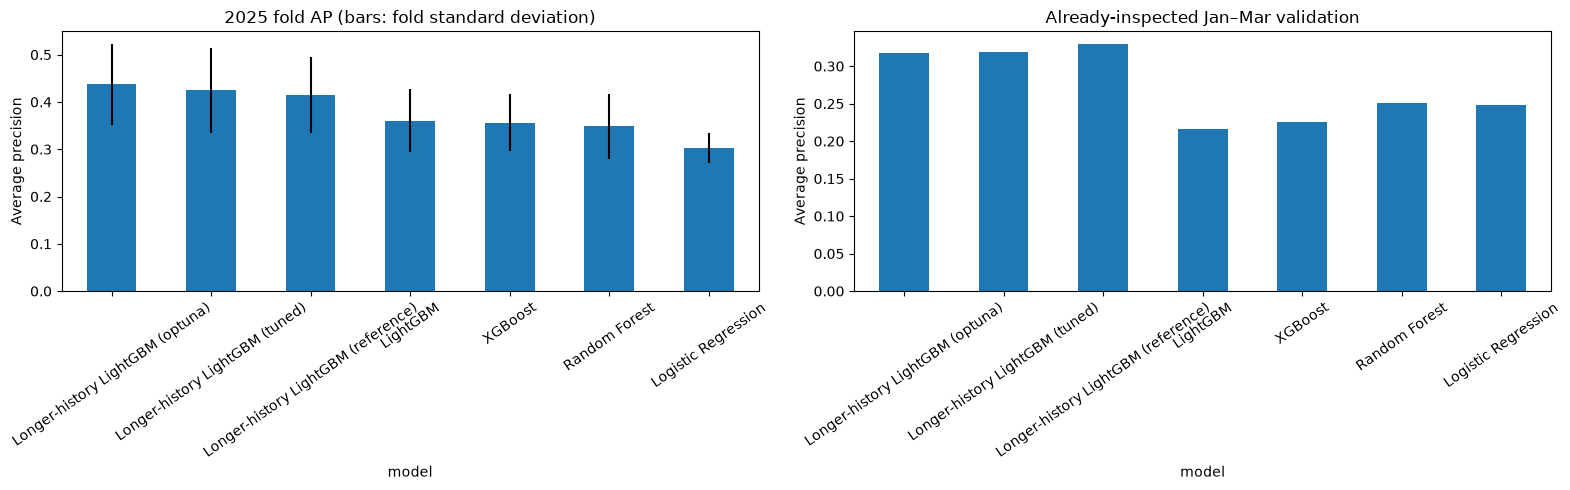

Saved comparison: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/10_model_comparison/20261028_180336_896083


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
comparison.plot.bar(x="model", y="mean_fold_ap", yerr="std_fold_ap", legend=False, ax=axes[0], rot=35)
axes[0].set(title="2025 fold AP (bars: fold standard deviation)", ylabel="Average precision")
comparison.plot.bar(x="model", y="validation_ap", legend=False, ax=axes[1], rot=35)
axes[1].set(title="Already-inspected Jan–Mar validation", ylabel="Average precision")
fig.tight_layout()
plt.show()
# Verify source studies and prepared inputs again before saving a new, separate comparison.
for relative, expected in reference["input_sha256"].items():
    if file_hash(cfg.PROJECT_ROOT / relative) != expected:
        raise ValueError("Prepared baseline input changed during comparison.")
for record in records.values():
    for path, expected in record["manifest"].get("additional_input_sha256", {}).items():
        if file_hash(cfg.resolve_input(path)) != expected:
            raise ValueError("Historical baseline input changed during comparison.")
    if file_hash(record["folder"] / "study_manifest.json") != record["manifest_sha256"]:
        raise ValueError("A source study changed during comparison.")
output = cfg.PROJECT_ROOT / "10_model_comparison" / datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
output.mkdir(parents=True, exist_ok=False)
comparison.to_csv(output / "model_comparison.csv", index=False)
fold_comparison.to_csv(output / "fold_comparison.csv", index=False)
group_comparison.to_csv(output / "group_comparison.csv", index=False)
group_baseline_metrics.to_csv(output / "group_baseline_metrics.csv", index=False)
group_baseline_comparison.to_csv(output / "group_baseline_comparison.csv", index=False)
fig.savefig(output / "model_comparison.png", dpi=160, bbox_inches="tight")
manifest = {"status": "completed", "candidate_under_fold_rule": selected_family,
            "deployment_changed": False, "test_evaluated": False, "supplementary_group_baseline": baseline_policy,
            "rule": "mean fold AP descending; fold AP standard deviation ascending; model name ascending",
            "studies": {k: {"folder": str(v["folder"].relative_to(cfg.PROJECT_ROOT)),
                             "manifest_sha256": v["manifest_sha256"]} for k, v in records.items()},
            "output_sha256": {p.name: file_hash(p) for p in output.iterdir()}}
(output / "comparison_manifest.json").write_text(json.dumps(manifest, indent=2))
print("Saved comparison:", output)

## Report interpretation

Present each technique in its model notebook, then use this table for the combined discussion. Include reference-versus-tuned results within each model, baseline comparisons, temporal variation, group support, false alerts and missed surges. Do not present the largest number as universal superiority. Fold standard deviation is not a confidence interval. Saved package versions identify implementation differences.

The existing longer-history dashboard is a separate experiment. Its original reference checkpoint is stored independently of the retired combined notebook. Opening that dashboard needs no retraining. Stages 11–13 use those saved artifacts; a new run without them does not yet constitute an integrated replacement dashboard. Before deploying a different candidate, regenerate and verify its matching explanations/exports and report its own evaluation evidence.

The longer-history reference/tuned rows are new 09b fits, not the older dashboard checkpoint. No new Optuna search is performed in 09b. Compare its fold `control_2025_ap` against longer-history AP to isolate training-history changes within each fixed setting. Repeated validation inspection limits selection claims even when row matching is exact.
